# HORDE: Hallucination-Oriented Relation-aware Decoding & Evidence Framework

**Full pipeline implementation** matching the design document and architecture diagram.

| Step | Name | Purpose |
|------|------|--------|
| 1 | Input | Image **I** + Question **Q** |
| 2 | Question-aware Visual Relation Modeling | Build optimized question-conditioned graph **G<sub>Q</sub>\*** |
| 3 | Counterfactual Evidence Injection | Produce positive evidence **E⁺** and counterfactual evidence **E⁻** |
| 4 | Relation-aware Contrastive Decoding | Baseline / Positive / Counterfactual branches → guided logits |
| 5 | Candidate Answer Generation & Verification | Extract predicted graph, verify, locally resample on conflict |
| 6 | Final Output | Verified answer (+ optional supporting relation graph) |

**Lightweight models used (no Qwen):**
- Reasoning / text: `Qwen/Qwen2.5-3B-Instruct`
- Vision-Language: `Qwen/Qwen2.5-VL-3B-Instruct`
- Open-vocab detection: `IDEA-Research/grounding-dino-base`
- Graph: NetworkX (+ optional OR-Tools when available)

> Run on a GPU (Colab T4 / similar). CPU works but is slow.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0 — Install & Imports

In [ ]:
# Optional: mount Google Drive if your dataset lives there (Colab)
# from google.colab import drive
# drive.mount('/content/drive')

import sys
print(sys.version)

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [ ]:
!pip install -q "transformers>=4.46.0" accelerate pillow networkx matplotlib opencv-python-headless num2words
# Optional (graph ILP). If install fails, pure-Python optimizer is used automatically.
!pip install -q ortools || echo "OR-Tools not installed — will use greedy graph optimizer"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 75.4 MB/s eta 0:00:00


In [ ]:
import os
import re
import gc
import json
import math
import copy
from pathlib import Path
from collections import defaultdict, Counter
from typing import List, Dict, Any, Optional, Tuple

import torch
import numpy as np
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import networkx as nx
import matplotlib.pyplot as plt

# Optional OR-Tools
try:
    from ortools.sat.python import cp_model
    HAS_ORTOOLS = True
except ImportError:
    HAS_ORTOOLS = False

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("OR-Tools available:", HAS_ORTOOLS)

Torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
OR-Tools available: True


In [ ]:
# cp -r '/content/drive/MyDrive/Research Paper/vlm' '/content/vlm'

import os
import zipfile

zip_path = '/content/drive/MyDrive/vlm/web_data.zip'
extract_path = '/content/vlm'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Files extracted to:", extract_path)



Extraction completed!
Files extracted to: /content/vlm


---
## Step 1 — Input (Image + Question)

Load a dataset record (or a single demo pair).  
Expected JSON record fields: `question_id`, `image`, `text` (question), `label` (optional ground truth).

In [ ]:
# ---------- CONFIG ----------
# Point these to your data. On Colab after copying the vlm folder:
DATA_ROOT = Path("/content/vlm")          # change if needed
JSON_PATH  = DATA_ROOT / "web_data" / "web_v1.json"
IMAGE_DIRS = [
    DATA_ROOT / "web_data" / "images",
    DATA_ROOT / "images",
    Path("/content"),
]

# Which sample to run (0-based index). Change freely.
SAMPLE_INDEX = 4

# Fallback demo when dataset is missing
DEMO_QUESTION = "What is the person doing?"
DEMO_IMAGE_URL = None  # set a local path if you have a demo image

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32

Loaded record #5
Question: Is there bird flying on a beach in the photo?
Image: /content/vlm/web_data/images/running_bird.jpg
Reference: no


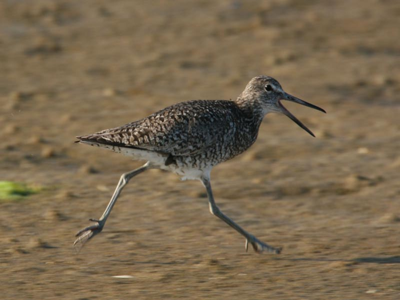

Question Q: Is there bird flying on a beach in the photo?


In [ ]:
def find_image(filename: str, search_dirs: List[Path]) -> Optional[Path]:
    for d in search_dirs:
        p = d / filename
        if p.exists():
            return p
        # recursive shallow search
        matches = list(d.rglob(filename)) if d.exists() else []
        if matches:
            return matches[0]
    return None


def load_dataset(json_path: Path):
    if not json_path.exists():
        return None
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    if isinstance(data, list):
        return data
    for key in ("data", "questions", "annotations"):
        if key in data and isinstance(data[key], list):
            return data[key]
    return None


records = load_dataset(JSON_PATH)

if records:
    record = records[min(SAMPLE_INDEX, len(records) - 1)]
    question = record.get("text") or record.get("question")
    image_name = record.get("image") or record.get("image_path")
    image_path = find_image(image_name, IMAGE_DIRS)
    if image_path is None:
        raise FileNotFoundError(f"Image not found: {image_name}")
    original_image = Image.open(image_path).convert("RGB")
    reference_answer = record.get("label") or record.get("answer")
    print(f"Loaded record #{record.get('question_id', SAMPLE_INDEX)}")
    print("Question:", question)
    print("Image:", image_path)
    print("Reference:", reference_answer)
else:
    # Synthetic demo so the notebook remains runnable without data
    print("Dataset not found — running synthetic demo (no real image).")
    question = DEMO_QUESTION
    # Create a simple placeholder image
    original_image = Image.new("RGB", (512, 384), color=(135, 206, 235))
    draw = ImageDraw.Draw(original_image)
    draw.ellipse([180, 80, 330, 280], fill=(139, 90, 43))   # "horse"
    draw.rectangle([230, 60, 280, 150], fill=(30, 30, 30))  # "person"
    draw.rectangle([50, 300, 460, 340], fill=(100, 100, 100))  # "fence"
    image_path = Path("/tmp/demo_horse.png")
    original_image.save(image_path)
    reference_answer = "riding"
    record = {
        "question_id": 0,
        "text": question,
        "image": "demo_horse.png",
        "label": reference_answer,
    }

display(original_image.resize((400, 300)))
print("Question Q:", question)

---
## Step 2 — Question-aware Visual Relation Modeling

Pipeline:
1. **Question Analysis** (Qwen2.5-3B) → relevant objects & required relations
2. **Open-vocabulary detection** (Grounding DINO Base) → boxes
3. **Multi-agent relation extraction** (4 independent Qwen2.5-VL-3B calls)
4. **Candidate graph** + agreement scores
5. **Relation scoring** (agreement · question relevance · visual support)
6. **Graph Space Optimization** → **G<sub>Q</sub>\***

### 2.1 Load reasoning model (SmolLM2)

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

REASONING_NAME = "Qwen/Qwen2.5-3B-Instruct"

print("Loading Qwen …")
reasoning_tokenizer = AutoTokenizer.from_pretrained(REASONING_NAME)
reasoning_model = AutoModelForCausalLM.from_pretrained(
    REASONING_NAME,
    torch_dtype=dtype,
    low_cpu_mem_usage=True,
).to(device)
reasoning_model.eval()
print("Qwen ready.")

Loading SmolLM2 …


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

SmolLM2 ready.


In [ ]:
def run_reasoning(prompt: str, max_new_tokens: int = 256, temperature: float = 0.2) -> str:
    """Generate text with Qwen (chat template)."""
    messages = [{"role": "user", "content": prompt}]
    input_text = reasoning_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = reasoning_tokenizer(input_text, return_tensors="pt").to(device)
    with torch.inference_mode():
        out = reasoning_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=temperature > 0,
            temperature=max(temperature, 1e-5),
            pad_token_id=reasoning_tokenizer.eos_token_id,
        )
    gen = out[0][inputs["input_ids"].shape[-1]:]
    return reasoning_tokenizer.decode(gen, skip_special_tokens=True).strip()


def extract_json(text: str) -> Any:
    """Best-effort JSON extraction from model output."""
    text = text.strip()
    # strip markdown fences
    text = re.sub(r"^```(?:json)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)
    # try whole string
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass
    # find first {…} or […]
    for pat in (r"\{[\s\S]*\}", r"\[[\s\S]*\]"):
        m = re.search(pat, text)
        if m:
            try:
                return json.loads(m.group(0))
            except json.JSONDecodeError:
                continue
    raise ValueError(f"Could not parse JSON from:\n{text[:400]}")

### 2.2 Question Analysis → objects & required relations

In [ ]:
qa_prompt = f"""Analyze the following visual question and return ONLY valid JSON.

Question: {question}

Return this exact schema:
{{
  "relevant_objects": ["object1", "object2", ...],
  "required_relations": [
    {{"type": "action|spatial|attribute|count", "description": "..."}},
    ...
  ],
  "question_type": "yes_no|open|counting|attribute|other",
  "critical_action": "the exact action verb from the question if any, else null (e.g. flying, running, riding)",
  "critical_attribute": "attribute to check if any (e.g. color, open, empty), else null",
  "count_target": "object to count if counting question, else null",
  "focus": "short phrase describing what the answer must cover"
}}

Rules:
- relevant_objects: concrete visual nouns that matter for the answer.
- If the question asks about an object that may be absent, still list it.
- ALWAYS extract action verbs (flying, running, riding, sitting, standing, holding...).
- ALWAYS extract attributes when asked (color, size, open/closed, empty/full).
- For counting questions set question_type=counting and count_target to the object name.
- Object present does NOT mean the asked ACTION or ATTRIBUTE is true.
- Keep lists short (max 6 objects, max 4 relations).
"""

raw_qa = run_reasoning(qa_prompt, max_new_tokens=300)
print("Raw question analysis:\n", raw_qa)

try:
    question_analysis = extract_json(raw_qa)
except Exception as e:
    print("Parse failed, using fallback:", e)
    words = re.findall(r"[a-zA-Z]+", question.lower())
    stop = {"is", "are", "the", "a", "an", "in", "on", "of", "to", "what", "where", "who", "how", "does", "do", "there", "photo", "image", "picture"}
    objs = [w for w in words if w not in stop and len(w) > 2][:5]
    action_verbs = {"flying", "running", "riding", "sitting", "standing", "holding", "walking", "eating", "wearing", "carrying"}
    found_action = next((w for w in words if w in action_verbs), None)
    qtype = "yes_no" if question.lower().strip().startswith(("is ", "are ", "does ", "do ")) else "open"
    if any(w in words for w in ("how", "many", "count", "number")):
        qtype = "counting"
    question_analysis = {
        "relevant_objects": objs or ["object"],
        "required_relations": [{"type": "action" if found_action else "spatial", "description": found_action or "main relation"}],
        "question_type": qtype,
        "critical_action": found_action,
        "critical_attribute": None,
        "count_target": objs[0] if qtype == "counting" and objs else None,
        "focus": question,
    }

# Ensure keys exist
question_analysis.setdefault("critical_action", None)
question_analysis.setdefault("critical_attribute", None)
question_analysis.setdefault("count_target", None)

print("\nParsed question analysis:")
print(json.dumps(question_analysis, indent=2))


Raw question analysis:
 {
  "relevant_objects": ["bird", "beach"],
  "required_relations": [
    {"type": "action", "description": "is flying"},
    {"type": "spatial", "description": "on the beach"}
  ],
  "question_type": "yes_no",
  "critical_action": "flying",
  "critical_attribute": null,
  "count_target": null,
  "focus": "Is there a bird flying on a beach in the photo?"
}

Parsed question analysis:
{
  "relevant_objects": [
    "bird",
    "beach"
  ],
  "required_relations": [
    {
      "type": "action",
      "description": "is flying"
    },
    {
      "type": "spatial",
      "description": "on the beach"
    }
  ],
  "question_type": "yes_no",
  "critical_action": "flying",
  "critical_attribute": null,
  "count_target": null,
  "focus": "Is there a bird flying on a beach in the photo?"
}


### 2.3 Open-vocabulary object detection (Grounding DINO Tiny)

In [ ]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DINO_NAME = "IDEA-Research/grounding-dino-base"

print("Loading Grounding DINO …")
dino_processor = AutoProcessor.from_pretrained(DINO_NAME)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    DINO_NAME,
    torch_dtype=dtype,   # or torch.float32 if you hit Half mismatches
).to(device)
dino_model.eval()
print("Grounding DINO ready.")

Loading Grounding DINO …


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Grounding DINO ready.


Query labels: ['bird', 'beach']
Detected 2 boxes:
  bird                 score=0.920  box=[138.8671875, 132.5, 656.25, 449.2578125]
  beach                score=0.427  box=[0.1953125, 1.03515625, 799.21875, 527.1533203125]


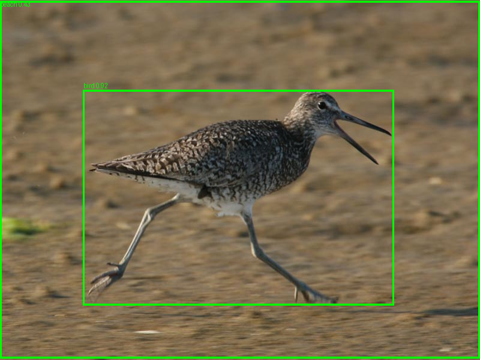

In [ ]:
def detect_objects(
    image: Image.Image,
    object_labels: List[str],
    box_threshold: float = 0.25,
    text_threshold: float = 0.25,
) -> List[Dict]:
    """Return list of {label, score, box=[x0,y0,x1,y1]}."""
    if not object_labels:
        return []

    # Grounding DINO expects lowercase labels separated by period
    text = " . ".join(o.lower().strip() for o in object_labels) + " ."
    inputs = dino_processor(images=image, text=text, return_tensors="pt")

    # Cast floating tensors to the model dtype (fixes float vs Half error)
    model_dtype = next(dino_model.parameters()).dtype
    for k, v in list(inputs.items()):
        if torch.is_floating_point(v):
            inputs[k] = v.to(device=device, dtype=model_dtype)
        else:
            inputs[k] = v.to(device=device)

    with torch.inference_mode():
        outputs = dino_model(**inputs)

    target_sizes = [image.size[::-1]]  # (h, w)

    # Support both old (box_threshold=) and new (threshold=) transformers APIs
    post_kwargs = dict(
        outputs=outputs,
        input_ids=inputs.input_ids,
        text_threshold=text_threshold,
        target_sizes=target_sizes,
    )
    try:
        results = dino_processor.post_process_grounded_object_detection(
            **post_kwargs, threshold=box_threshold
        )[0]
    except TypeError:
        results = dino_processor.post_process_grounded_object_detection(
            **post_kwargs, box_threshold=box_threshold
        )[0]

    detections = []
    boxes = results["boxes"].detach().cpu().tolist()
    scores = results["scores"].detach().cpu().tolist()
    labels = results.get("text_labels") or results.get("labels") or []
    if hasattr(labels, "tolist"):
        labels = labels.tolist()

    for box, score, label in zip(boxes, scores, labels):
        detections.append({
            "label": label if isinstance(label, str) else str(label),
            "score": float(score),
            "box": [float(x) for x in box],
        })
    return detections


object_labels = question_analysis.get("relevant_objects", [])
print("Query labels:", object_labels)

detections = detect_objects(original_image, object_labels)
print(f"Detected {len(detections)} boxes:")
for d in detections:
    print(f"  {d['label']:20s} score={d['score']:.3f}  box={d['box']}")

# Visualize
vis = original_image.copy()
draw = ImageDraw.Draw(vis)
for d in detections:
    box = d["box"]
    draw.rectangle(box, outline="lime", width=3)
    draw.text((box[0], max(0, box[1] - 12)), f"{d['label']} {d['score']:.2f}", fill="lime")
display(vis.resize((480, 360)))

In [ ]:
# Free DINO to save VRAM before loading VLM
del dino_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("DINO released.")

DINO released.


### 2.4 Load Vision-Language model (SmolVLM2)

In [ ]:
# ========== FIXED SmolVLM2 load + run_vlm ==========
import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText
import transformers.models.smolvlm.processing_smolvlm as smol_proc
import num2words

if not hasattr(smol_proc, "num2words"):
    smol_proc.num2words = num2words.num2words

VLM_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"
# Prefer bfloat16 on GPU (model card default); fall back to float16/float32
if device == "cuda" and torch.cuda.is_bf16_supported():
    vlm_dtype = torch.bfloat16
elif device == "cuda":
    vlm_dtype = torch.float16
else:
    vlm_dtype = torch.float32

print("Loading Qwen2.5-VL …")
vlm_processor = AutoProcessor.from_pretrained(VLM_NAME)
# CRITICAL: disable splitting so vision tokens match <image> placeholders
if hasattr(vlm_processor, "image_processor"):
    vlm_processor.image_processor.do_image_splitting = False
    # keep patches at the model's native max size
    if hasattr(vlm_processor.image_processor, "max_image_size"):
        print("max_image_size:", vlm_processor.image_processor.max_image_size)
    if hasattr(vlm_processor.image_processor, "size"):
        print("size:", vlm_processor.image_processor.size)

vlm_model = AutoModelForImageTextToText.from_pretrained(
    VLM_NAME,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    low_cpu_mem_usage=True,
).to(device)
vlm_model.eval()
print("Qwen2.5-VL ready on", device, "dtype=", vlm_dtype)

Loading SmolVLM2 …


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

SmolVLM2 ready on cuda dtype= torch.bfloat16


In [ ]:
import types
import torch

def _safe_inputs_merger(self, input_ids, inputs_embeds, image_hidden_states):
    """
    Replacement for Qwen2.5-VL inputs_merger that does NOT assume
    image token count is divisible by vision patch_size (14).
    Merges image features sequentially into positions marked by image_token_id.
    """
    if image_hidden_states is None:
        return inputs_embeds

    # Normalize to (num_image_tokens, hidden)
    if image_hidden_states.dim() == 3:
        # (num_images, seq, hidden) -> (num_images*seq, hidden)
        image_hidden_states = image_hidden_states.reshape(-1, image_hidden_states.shape[-1])
    elif image_hidden_states.dim() != 2:
        image_hidden_states = image_hidden_states.reshape(-1, image_hidden_states.shape[-1])

    image_token_id = self.config.image_token_id
    batch_size, seq_len, hidden = inputs_embeds.shape
    new_embeds = inputs_embeds.clone()

    offset = 0
    for b in range(batch_size):
        if input_ids is not None:
            mask = input_ids[b] == image_token_id
        else:
            # fallback: compare embedding to image token embedding
            image_tok_emb = self.get_input_embeddings()(
                torch.tensor(image_token_id, device=inputs_embeds.device)
            )
            mask = (inputs_embeds[b] == image_tok_emb).all(dim=-1)

        idx = mask.nonzero(as_tuple=False).flatten()
        n = idx.numel()
        if n == 0:
            continue
        if offset + n > image_hidden_states.shape[0]:
            raise RuntimeError(
                f"Not enough image features: need {offset + n}, "
                f"have {image_hidden_states.shape[0]}"
            )
        new_embeds[b, idx] = image_hidden_states[offset:offset + n].to(new_embeds.dtype)
        offset += n

    return new_embeds


# Apply patch to the loaded model (covers common attribute paths)
_patched = False
for obj in (
    vlm_model,
    getattr(vlm_model, "model", None),
    getattr(getattr(vlm_model, "model", None), "model", None),
):
    if obj is None:
        continue
    if hasattr(obj, "inputs_merger"):
        obj.inputs_merger = types.MethodType(_safe_inputs_merger, obj)
        _patched = True
        print("Patched inputs_merger on:", type(obj).__name__)

if not _patched:
    print("WARNING: could not find inputs_merger to patch")

# Re-define a simple run_vlm that uses the patched model
def run_vlm(image, prompt, max_new_tokens=128, temperature=0.0):
    image = image.convert("RGB").resize((384, 384), Image.BICUBIC)

    if hasattr(vlm_processor, "image_processor"):
        vlm_processor.image_processor.do_image_splitting = False

    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": prompt},
        ],
    }]
    text = vlm_processor.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=False
    )
    inputs = vlm_processor(text=text, images=[image], return_tensors="pt")

    moved = {}
    for k, v in inputs.items():
        if not hasattr(v, "to"):
            moved[k] = v
            continue
        if torch.is_floating_point(v):
            moved[k] = v.to(device=device, dtype=vlm_dtype)
        else:
            moved[k] = v.to(device=device)
    inputs = moved

    gen_kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": bool(temperature and temperature > 0),
        "pad_token_id": vlm_processor.tokenizer.eos_token_id,
    }
    if gen_kwargs["do_sample"]:
        gen_kwargs["temperature"] = max(float(temperature), 1e-5)

    with torch.inference_mode():
        out = vlm_model.generate(**inputs, **gen_kwargs)

    in_len = inputs["input_ids"].shape[-1]
    return vlm_processor.tokenizer.decode(out[0][in_len:], skip_special_tokens=True).strip()


_test = run_vlm(
    original_image,
    "What objects are in this image? Reply in one short sentence.",
    max_new_tokens=32,
)
print("Smoke test OK →", _test[:200])
print("run_vlm ready.")

Smoke test OK → bird
run_vlm ready.


In [ ]:
print(type(vlm_model))
print([a for a in dir(vlm_model) if "merger" in a.lower() or "model" == a])
print(type(getattr(vlm_model, "model", None)))

<class 'transformers.models.qwen2_5_vl.modeling_qwen2_5_vl.Qwen2_5_VLForConditionalGeneration'>
['model']
<class 'transformers.models.qwen2_5_vl.modeling_qwen2_5_vl.Qwen2_5_VLModel'>


### 2.5 Multi-agent relation extraction (4 independent agents)

Each agent sees the same image + question and predicts local/action relations.  
If an object/relation is absent the agent should answer negatively ("no" / "not present").

In [ ]:
NUM_AGENTS = 4

detected_names = sorted({d["label"].lower() for d in detections}) or object_labels
_crit_action = question_analysis.get("critical_action")
_crit_attr = question_analysis.get("critical_attribute")
_count_tgt = question_analysis.get("count_target")
_qtype = str(question_analysis.get("question_type", "")).lower()

relation_prompt_template = """You are a careful visual inspector.
Question: {question}

Relevant objects: {objects}
Detected objects (may be incomplete): {detected}
Critical action to check: {crit_action}
Critical attribute to check: {crit_attr}
Count target (if any): {count_target}

List ONLY relations that are clearly supported by the IMAGE (not by the question text).
Return ONLY a JSON list:
[
  {{"subject": "...", "relation": "...", "object": "...", "type": "action|spatial|attribute|count"}}
]

Hard rules:
1. If an object is NOT visible, do NOT invent it.
2. If the question asks about an ACTION (flying, running, riding...), you MUST include that action as a relation ONLY if it is truly visible. If the animal/person is doing a DIFFERENT action (e.g. running not flying), report the TRUE action (e.g. bird running_on beach) and do NOT report the false action.
3. Object present ≠ action true. Bird on beach does NOT mean bird is flying.
4. For attributes, use type "attribute" (e.g. cup is empty).
5. For counting, you may include {{"subject":"count","relation":"equals","object":"N","type":"count"}} using visible instances only.
6. Prefer short verbs: flying, running, riding, sitting_on, standing_beside, next_to, on, under, holding, wearing.
7. Empty list [] is valid. Output ONLY JSON, no markdown.
"""

agent_predictions: List[List[Dict]] = []

for agent_id in range(NUM_AGENTS):
    prompt = relation_prompt_template.format(
        question=question,
        objects=", ".join(object_labels),
        detected=", ".join(detected_names) if detected_names else "none",
        crit_action=_crit_action or "none",
        crit_attr=_crit_attr or "none",
        count_target=_count_tgt or "none",
    )
    temp = 0.15 + 0.1 * agent_id
    raw = run_vlm(original_image, prompt, max_new_tokens=200, temperature=temp)
    print(f"\n--- Agent {agent_id + 1} raw ---")
    print(raw[:400])
    try:
        preds = extract_json(raw)
        if isinstance(preds, dict):
            preds = preds.get("relations", preds.get("relations_list", [preds]))
        if not isinstance(preds, list):
            preds = []
        clean = []
        for p in preds:
            if not isinstance(p, dict):
                continue
            s = str(p.get("subject", "")).strip().lower()
            r = str(p.get("relation", "")).strip().lower().replace(" ", "_")
            o = str(p.get("object", "")).strip().lower()
            t = str(p.get("type", "action")).strip().lower()
            if s and r and o:
                clean.append({"subject": s, "relation": r, "object": o, "type": t})
        preds = clean
    except Exception as e:
        print(f"  Agent {agent_id + 1} parse error: {e}")
        preds = []
    agent_predictions.append(preds)
    print(f"  → {len(preds)} relations")



--- Agent 1 raw ---
[]
  → 0 relations

--- Agent 2 raw ---
[]
  → 0 relations

--- Agent 3 raw ---
[]
  → 0 relations

--- Agent 4 raw ---
[]
  → 0 relations


### 2.6 Candidate graph + agreement scores

In [ ]:
def relation_key(rel: Dict) -> Tuple[str, str, str]:
    return (rel["subject"], rel["relation"], rel["object"])


# Aggregate
agg = defaultdict(lambda: {"count": 0, "agents": [], "type": "action"})
for aid, preds in enumerate(agent_predictions):
    seen = set()
    for p in preds:
        k = relation_key(p)
        if k in seen:
            continue
        seen.add(k)
        agg[k]["count"] += 1
        agg[k]["agents"].append(aid + 1)
        agg[k]["type"] = p.get("type", "action")

relation_candidates = []
for (subj, rel, obj), info in agg.items():
    agreement = info["count"] / NUM_AGENTS
    relation_candidates.append({
        "subject": subj,
        "relation": rel,
        "object": obj,
        "type": info["type"],
        "agreement_count": info["count"],
        "agreement_score": agreement,
        "supporting_agents": info["agents"],
    })

relation_candidates.sort(key=lambda x: -x["agreement_score"])
print(f"Unique candidate relations: {len(relation_candidates)}")
for r in relation_candidates:
    print(
        f"  {r['subject']} --[{r['relation']}]--> {r['object']}  "
        f"agreement={r['agreement_count']}/{NUM_AGENTS} ({r['agreement_score']*100:.0f}%)"
    )

Unique candidate relations: 0


### 2.7 Relation scoring (agreement + question relevance + visual evidence)

In [ ]:
def question_relevance(rel: Dict, analysis: Dict) -> float:
    """Heuristic relevance of a relation to the question."""
    focus = (analysis.get("focus") or "").lower()
    q = question.lower()
    objs = set(o.lower() for o in analysis.get("relevant_objects", []))
    score = 0.3  # base
    if rel["subject"] in objs or rel["object"] in objs:
        score += 0.3
    # lexical overlap with question / focus
    tokens = set(re.findall(r"[a-z]+", rel["relation"] + " " + rel["subject"] + " " + rel["object"]))
    q_tokens = set(re.findall(r"[a-z]+", q + " " + focus))
    overlap = len(tokens & q_tokens) / max(1, len(tokens))
    score += 0.4 * overlap
    return min(1.0, score)


def visual_support(rel: Dict, detections: List[Dict]) -> float:
    """1.0 if both endpoints detected, 0.5 if one, 0.2 if none."""
    labels = {d["label"].lower() for d in detections}
    s_hit = any(rel["subject"] in lab or lab in rel["subject"] for lab in labels)
    o_hit = any(rel["object"] in lab or lab in rel["object"] for lab in labels)
    if s_hit and o_hit:
        return 1.0
    if s_hit or o_hit:
        return 0.55
    return 0.2


for r in relation_candidates:
    r["q_relevance"] = question_relevance(r, question_analysis)
    r["visual_score"] = visual_support(r, detections)
    # Combined score used by the optimizer
    r["score"] = (
        0.40 * r["agreement_score"]
        + 0.35 * r["q_relevance"]
        + 0.25 * r["visual_score"]
    )

relation_candidates.sort(key=lambda x: -x["score"])
print("Scored relations:")
for r in relation_candidates:
    print(
        f"  {r['subject']:12s} --[{r['relation']:16s}]--> {r['object']:12s}  "
        f"score={r['score']:.3f}  (agr={r['agreement_score']:.2f} "
        f"qrel={r['q_relevance']:.2f} vis={r['visual_score']:.2f})"
    )

Scored relations:


### 2.8 Graph Space Optimization → G_Q*

Select a compact, consistent, question-relevant subset of relations.  
Uses OR-Tools CP-SAT when available; otherwise a greedy + consistency filter.

In [ ]:
def optimize_relation_graph(
    candidates: List[Dict],
    max_relations: int = 6,
    min_score: float = 0.25,
) -> List[Dict]:
    """
    Select a subset of relations that maximises total score under:
    - at most max_relations
    - no contradictory pairs on the same (subject, object) with different relations
    - prefer higher-scoring edges
    """
    # filter weak candidates early
    cands = [c for c in candidates if c["score"] >= min_score]
    if not cands:
        return []

    if HAS_ORTOOLS:
        model = cp_model.CpModel()
        n = len(cands)
        x = [model.NewBoolVar(f"r{i}") for i in range(n)]
        # maximise weighted score (scale to ints)
        model.Maximize(sum(int(c["score"] * 1000) * x[i] for i, c in enumerate(cands)))
        model.Add(sum(x) <= max_relations)
        # mutual exclusion: same endpoints different relations
        pairs = defaultdict(list)
        for i, c in enumerate(cands):
            pairs[(c["subject"], c["object"])].append(i)
        for idxs in pairs.values():
            if len(idxs) > 1:
                model.Add(sum(x[i] for i in idxs) <= 1)
        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = 5.0
        status = solver.Solve(model)
        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            return [cands[i] for i in range(n) if solver.Value(x[i]) == 1]

    # ---- Greedy fallback ----
    selected = []
    used_endpoints = set()  # (subj, obj) pairs already taken
    for c in sorted(cands, key=lambda z: -z["score"]):
        ep = (c["subject"], c["object"])
        if ep in used_endpoints:
            continue
        selected.append(c)
        used_endpoints.add(ep)
        if len(selected) >= max_relations:
            break
    return selected


optimized_relations = optimize_relation_graph(relation_candidates)
print(f"Optimized G_Q* has {len(optimized_relations)} relations:")
for r in optimized_relations:
    print(f"  {r['subject']} --[{r['relation']}]--> {r['object']}  (score={r['score']:.3f})")

Optimized G_Q* has 0 relations:


In [ ]:
# Build NetworkX MultiDiGraph for G_Q*
G_Q_star = nx.MultiDiGraph()
for idx, r in enumerate(optimized_relations):
    G_Q_star.add_edge(
        r["subject"],
        r["object"],
        key=idx,
        relation=r["relation"],
        score=r["score"],
        agreement_score=r["agreement_score"],
        type=r.get("type", "action"),
    )

print("G_Q* nodes:", list(G_Q_star.nodes()))
print("G_Q* edges:", [
    (u, v, d["relation"]) for u, v, d in G_Q_star.edges(data=True)
])

# Optional: draw the graph
if G_Q_star.number_of_edges() > 0:
    plt.figure(figsize=(7, 4))
    pos = nx.spring_layout(G_Q_star, seed=42)
    nx.draw(G_Q_star, pos, with_labels=True, node_color="lightblue",
            node_size=1800, font_size=9, arrows=True)
    edge_labels = {(u, v): d["relation"] for u, v, d in G_Q_star.edges(data=True)}
    nx.draw_networkx_edge_labels(G_Q_star, pos, edge_labels=edge_labels, font_size=8)
    plt.title("Optimized question-conditioned relation graph G_Q*")
    plt.axis("off")
    plt.show()

G_Q* nodes: []
G_Q* edges: []


---
## Step 3 — Counterfactual Evidence Injection

1. **Positive evidence E⁺** = relations from G_Q* that are visually supported.
2. **Alternative relations** suggested by the reasoning model (for hallucination probing).
3. **Counterfactual evidence E⁻** produced by:
   - relation swapping
   - relation removal
   - object masking
   - multi-object disruption

These evidence sets later condition the three decoding branches.

In [ ]:
# 3.1 Positive evidence from G_Q*
E_plus = []
for r in optimized_relations:
    if r["visual_score"] >= 0.5:
        E_plus.append({
            "subject": r["subject"],
            "relation": r["relation"],
            "object": r["object"],
            "score": r["score"],
        })

print("Positive evidence E⁺:")
for e in E_plus:
    print(f"  {e['subject']} --[{e['relation']}]--> {e['object']}")
if not E_plus:
    print("  (empty — no strongly supported relations)")

Positive evidence E⁺:
  (empty — no strongly supported relations)


In [ ]:
# 3.2 Ask reasoning model for plausible alternative (counterfactual) relations
alt_prompt = f"""Given the question and the supported visual relations, propose 2-4 ALTERNATIVE relations
that would be plausible answers if the image were different (hallucination candidates).

Question: {question}
Supported relations:
{json.dumps(E_plus, indent=2)}

Return ONLY a JSON list:
[
  {{"subject": "...", "relation": "...", "object": "...", "why_alternative": "..."}}
]
"""

raw_alt = run_reasoning(alt_prompt, max_new_tokens=250)
print("Alternative relations raw:\n", raw_alt)

try:
    alternative_relations = extract_json(raw_alt)
    if isinstance(alternative_relations, dict):
        alternative_relations = alternative_relations.get("alternatives", [])
    if not isinstance(alternative_relations, list):
        alternative_relations = []
except Exception:
    alternative_relations = []

# fallback alternatives if model returned nothing
if not alternative_relations and E_plus:
    for e in E_plus[:2]:
        alternative_relations.append({
            "subject": e["subject"],
            "relation": "standing_beside",
            "object": e["object"],
            "why_alternative": "common spatial alternative to action relation",
        })

print("\nAlternative relations:")
for a in alternative_relations:
    print(f"  {a.get('subject')} --[{a.get('relation')}]--> {a.get('object')}")

Alternative relations raw:
 [
  {
    "subject": "bird",
    "relation": "is flying over",
    "object": "beach",
    "why_alternative": "The image might show the bird flying over the beach instead of on it."
  },
  {
    "subject": "bird",
    "relation": "is perched on",
    "object": "tree",
    "why_alternative": "The image could depict the bird perched on a tree near the beach, rather than on the sand or rocks."
  },
  {
    "subject": "bird",
    "relation": "is flying above",
    "object": "waves",
    "why_alternative": "The bird might be flying above the waves near the beach, not necessarily on the sand."
  }
]

Alternative relations:
  bird --[is flying over]--> beach
  bird --[is perched on]--> tree
  bird --[is flying above]--> waves


Counterfactual descriptions: 7
Counterfactual images: ['mask_bird', 'disrupt_bird', 'mask_beach', 'disrupt_beach']

Example counterfactual image (mask_bird):


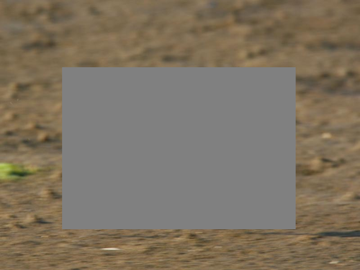

In [ ]:
import cv2

def mask_object(image: Image.Image, box: List[float], fill=(128, 128, 128)) -> Image.Image:
    """Gray-out a bounding box region."""
    img = image.copy()
    draw = ImageDraw.Draw(img)
    draw.rectangle(box, fill=fill)
    return img


def disrupt_region(image: Image.Image, box: List[float], strength: int = 25) -> Image.Image:
    """Blur + noise a region to break object identity."""
    img = np.array(image.convert("RGB")).copy()
    x0, y0, x1, y1 = [int(v) for v in box]
    h, w = img.shape[:2]
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(w, x1), min(h, y1)
    if x1 <= x0 or y1 <= y0:
        return image
    region = img[y0:y1, x0:x1]
    region = cv2.GaussianBlur(region, (15, 15), 0)
    noise = np.random.randint(-strength, strength + 1, region.shape, dtype=np.int16)
    region = np.clip(region.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    img[y0:y1, x0:x1] = region
    return Image.fromarray(img)


def find_box_for_label(label: str, detections: List[Dict]) -> Optional[List[float]]:
    label = label.lower()
    for d in detections:
        if label in d["label"].lower() or d["label"].lower() in label:
            return d["box"]
    return None


# 3.3 Build counterfactual visual evidence variants
counterfactual_images = {}
E_minus_descriptions = []

# (a) Relation-swap description (textual)
for alt in alternative_relations[:3]:
    E_minus_descriptions.append({
        "kind": "relation_swap",
        "subject": alt.get("subject"),
        "relation": alt.get("relation"),
        "object": alt.get("object"),
        "note": alt.get("why_alternative", ""),
    })

# (b) Object masking / disruption images
for d in detections[:3]:
    box = d["box"]
    masked = mask_object(original_image, box)
    disrupted = disrupt_region(original_image, box)
    key_m = f"mask_{d['label']}"
    key_d = f"disrupt_{d['label']}"
    counterfactual_images[key_m] = masked
    counterfactual_images[key_d] = disrupted
    E_minus_descriptions.append({
        "kind": "object_mask",
        "target": d["label"],
        "image_key": key_m,
    })
    E_minus_descriptions.append({
        "kind": "multi_object_disruption",
        "target": d["label"],
        "image_key": key_d,
    })

# (c) Relation-removal textual evidence
for e in E_plus[:2]:
    E_minus_descriptions.append({
        "kind": "relation_removal",
        "removed": f"{e['subject']} --[{e['relation']}]--> {e['object']}",
    })

print(f"Counterfactual descriptions: {len(E_minus_descriptions)}")
print(f"Counterfactual images: {list(counterfactual_images.keys())}")

# Show one example
if counterfactual_images:
    k = next(iter(counterfactual_images))
    print(f"\nExample counterfactual image ({k}):")
    display(counterfactual_images[k].resize((360, 270)))

In [ ]:
# Textual prompts that will be prepended to the VLM for each branch
def format_evidence_text(evidence_list: List[Dict], title: str) -> str:
    if not evidence_list:
        return f"{title}: none.\n"
    lines = [f"{title}:"]
    for e in evidence_list:
        if "relation" in e and "subject" in e:
            lines.append(f"- {e['subject']} {e['relation']} {e['object']}")
        elif "removed" in e:
            lines.append(f"- REMOVED: {e['removed']}")
        elif "target" in e:
            lines.append(f"- {e['kind']}: {e['target']}")
        else:
            lines.append(f"- {e}")
    return "\n".join(lines) + "\n"

positive_text = format_evidence_text(E_plus, "Supported visual relations (use these)")
counterfactual_text = format_evidence_text(
    [e for e in E_minus_descriptions if e.get("kind") in ("relation_swap", "relation_removal")],
    "Counterfactual / unsupported relations (DO NOT use these as facts)",
)

print("--- Positive conditioning ---")
print(positive_text)
print("--- Counterfactual conditioning ---")
print(counterfactual_text)

--- Positive conditioning ---
Supported visual relations (use these): none.

--- Counterfactual conditioning ---
Counterfactual / unsupported relations (DO NOT use these as facts):
- bird is flying over beach
- bird is perched on tree
- bird is flying above waves



---
## Step 4 — Relation-aware Contrastive Decoding

Three parallel branches over the same image + question:

| Branch | Conditioning |
|--------|--------------|
| Baseline | image + question only |
| Positive | image + question + E⁺ |
| Counterfactual | image + question + E⁻ |

Logits are combined at each step:

$$
\ell_{\text{guided}} = \ell_{\text{base}} + \alpha\,(\ell_{\text{pos}} - \ell_{\text{base}}) - \beta\,(\ell_{\text{cf}} - \ell_{\text{base}})
$$

(equivalent form: $(1-\alpha)\ell_{\text{base}} + \alpha\ell_{\text{pos}} - \beta(\ell_{\text{cf}}-\ell_{\text{base}})$)

Then the next token is chosen from the guided distribution.

In [ ]:
def build_vlm_inputs(image: Image.Image, prompt: str):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": prompt},
        ],
    }]
    text = vlm_processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = vlm_processor(
        text=text,
        images=[image],
        return_tensors="pt",
    )
    return {k: v.to(device) for k, v in inputs.items()}


_is_yes_no = str(question_analysis.get("question_type", "")).lower() in {
    "yes_no", "yes/no", "boolean"
} or question.strip().lower().startswith(("is ", "are ", "does ", "do ", "can ", "will "))

if _is_yes_no:
    base_prompt = (
        f"Answer the question with ONLY one word: yes or no.\n"
        f"Do not repeat the word. Do not explain.\n\n"
        f"Question: {question}\n"
        f"Answer:"
    )
    pos_prompt = (
        f"{positive_text}\n"
        f"Using only supported relations, answer with ONLY one word: yes or no.\n"
        f"Do not repeat. Do not explain.\n\n"
        f"Question: {question}\n"
        f"Answer:"
    )
    cf_prompt = (
        f"{counterfactual_text}\n"
        f"Ignore unsupported relations. Answer with ONLY one word: yes or no.\n"
        f"Do not repeat. Do not explain.\n\n"
        f"Question: {question}\n"
        f"Answer:"
    )
else:
    base_prompt = f"Answer the question based only on the image. Be concise.\n\nQuestion: {question}"
    pos_prompt  = (
        f"{positive_text}\n"
        f"Answer the question using the supported relations above. Be concise.\n\n"
        f"Question: {question}"
    )
    cf_prompt   = (
        f"{counterfactual_text}\n"
        f"The relations listed above are NOT supported by the image. "
        f"Do not treat them as true. Answer only from what is visible.\n\n"
        f"Question: {question}"
    )

print("Yes/no question:", _is_yes_no)
print("Prompts prepared for three branches.")


Yes/no question: True
Prompts prepared for three branches.


In [ ]:
def contrastive_decode(
    image: Image.Image,
    base_prompt: str,
    pos_prompt: str,
    cf_prompt: str,
    alpha: float = 0.6,
    beta: float = 0.4,
    max_new_tokens: int = 16,
    temperature: float = 0.0,
) -> str:
    """
    Contrastive decoding for Qwen2.5-VL.
    Rebuilds full multimodal inputs each step so RoPE / masks stay aligned.
    Stops early on clear yes/no and blocks token repetition (yesyesyes...).
    """
    image = image.convert("RGB")
    eos_id = vlm_processor.tokenizer.eos_token_id
    generated: list[int] = []

    def logits_for(prompt: str, partial_text: str):
        full_prompt = prompt
        if partial_text:
            full_prompt = prompt.rstrip() + " " + partial_text

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": full_prompt},
            ],
        }]
        try:
            inputs = vlm_processor.apply_chat_template(
                messages,
                add_generation_prompt=True,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
            )
        except Exception:
            text = vlm_processor.apply_chat_template(
                messages, add_generation_prompt=True, tokenize=False
            )
            inputs = vlm_processor(text=text, images=[image], return_tensors="pt")

        model_dtype = next(vlm_model.parameters()).dtype
        moved = {}
        for k, v in inputs.items():
            if not hasattr(v, "to"):
                moved[k] = v
                continue
            if torch.is_floating_point(v):
                moved[k] = v.to(device=device, dtype=model_dtype)
            else:
                moved[k] = v.to(device=device)
        inputs = moved

        with torch.inference_mode():
            out = vlm_model(**inputs)
        return out.logits[:, -1, :].float()

    for step in range(max_new_tokens):
        partial = vlm_processor.tokenizer.decode(
            generated, skip_special_tokens=True
        )

        base_logits = logits_for(base_prompt, partial)
        pos_logits  = logits_for(pos_prompt, partial)
        cf_logits   = logits_for(cf_prompt, partial)

        guided = (
            base_logits
            + alpha * (pos_logits - base_logits)
            - beta  * (cf_logits - base_logits)
        )

        # Block immediate repetition of the last token (stops yesyesyes...)
        if generated:
            guided[0, generated[-1]] = -1e9

        if temperature and temperature > 1e-5:
            probs = torch.softmax(guided / temperature, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
        else:
            next_token = torch.argmax(guided, dim=-1, keepdim=True)

        token_id = int(next_token.item())
        if token_id == eos_id:
            break
        generated.append(token_id)

        text_so_far = vlm_processor.tokenizer.decode(
            generated, skip_special_tokens=True
        ).strip().lower()

        # Stop as soon as we have a clean yes/no
        if text_so_far in {"yes", "no", "yes.", "no."}:
            break
        # Stop if yes/no appears once as a whole word
        yn = re.findall(r"\b(yes|no)\b", text_so_far)
        if len(yn) == 1 and len(text_so_far) <= 8:
            break
        # Safety: if the same word is glued (yesyes), collapse and stop
        if re.fullmatch(r"(yes)+", text_so_far.replace(" ", "")):
            generated = vlm_processor.tokenizer.encode(
                "yes", add_special_tokens=False
            )
            break
        if re.fullmatch(r"(no)+", text_so_far.replace(" ", "")):
            generated = vlm_processor.tokenizer.encode(
                "no", add_special_tokens=False
            )
            break

    answer = vlm_processor.tokenizer.decode(
        generated, skip_special_tokens=True
    ).strip()

    # Final cleanup for repeated yes/no
    low = answer.lower().replace(" ", "")
    if re.fullmatch(r"(yes)+[\.!]?", low):
        answer = "yes"
    elif re.fullmatch(r"(no)+[\.!]?", low):
        answer = "no"
    return answer


_max_tok = 8 if _is_yes_no else 40
print(f"Running contrastive decoding (max_new_tokens={_max_tok}) …")
candidate_answer = contrastive_decode(
    original_image,
    base_prompt,
    pos_prompt,
    cf_prompt,
    alpha=0.6,
    beta=0.4,
    max_new_tokens=_max_tok,
)
print("\nCandidate answer (contrastive):", candidate_answer)


Running contrastive decoding (max_new_tokens=8) …

Candidate answer (contrastive): no


In [ ]:
# Also produce a plain baseline answer for comparison
baseline_answer = run_vlm(
    original_image,
    base_prompt,
    max_new_tokens=40,
    temperature=0.0,
)
print("Baseline answer:", baseline_answer)
print("HORDE candidate:", candidate_answer)

Baseline answer: No
HORDE candidate: no


---
## Step 5 — Candidate Answer Generation & Verification

1. Extract a **predicted relation graph Ĝ** from the candidate answer (SmolLM2 + structured parse).
2. Compare Ĝ against **G_Q\*** and re-check claims against the original image.
3. Label each claim **Supported / Conflicting / Uncertain**.
4. On conflict: **identify inconsistent span → locally resample** (same contrastive decoder) → re-verify.
5. Retry up to **N** times; if still unresolved → cautious answer / abstention.

In [ ]:
def extract_relations_from_answer(answer: str, question: str) -> List[Dict]:
    prompt = f"""Extract the visual claims (subject-relation-object) implied by the answer.

Question: {question}
Answer: {answer}

Return ONLY a JSON list:
[
  {{"subject": "...", "relation": "...", "object": "...", "span": "exact phrase from answer"}}
]
If the answer is a simple yes/no with no explicit relation, return [].
"""
    raw = run_reasoning(prompt, max_new_tokens=200)
    try:
        data = extract_json(raw)
        if isinstance(data, dict):
            data = data.get("claims", data.get("relations", []))
        if not isinstance(data, list):
            return []
        out = []
        for c in data:
            if not isinstance(c, dict):
                continue
            s = str(c.get("subject", "")).strip().lower()
            r = str(c.get("relation", "")).strip().lower().replace(" ", "_")
            o = str(c.get("object", "")).strip().lower()
            span = str(c.get("span", "")).strip()
            if s and r and o:
                out.append({"subject": s, "relation": r, "object": o, "span": span})
        return out
    except Exception:
        return []


def verify_claims_with_vlm(
    image: Image.Image,
    answer: str,
    claims: List[Dict],
    gq_star: List[Dict],
    question_text: str = "",
    critical_action: str = None,
) -> Dict:
    """Return acceptable / not_acceptable only (no Supported/Conflicting/Uncertain)."""
    claims_txt = json.dumps(claims, indent=2) if claims else "[]"
    gq_txt = json.dumps(
        [{"subject": r["subject"], "relation": r["relation"], "object": r["object"]} for r in gq_star],
        indent=2,
    )
    q = question_text or question
    prompt = f"""Check if this answer is acceptable for the image.

Question: {q}
Answer: {answer}
Claims: {claims_txt}
Image relations: {gq_txt}
Critical action (must be true for yes): {critical_action or "none"}

Rules:
- Judge only from the image.
- Object present does not mean the action is true.
- If the answer matches the image, it is acceptable.
- If the answer is wrong for the image, it is not_acceptable.

Return ONLY JSON:
{{
  "acceptable": true or false,
  "recommended_answer": "yes or no or short corrected answer"
}}
"""
    raw = run_vlm(image, prompt, max_new_tokens=200, temperature=0.1)
    try:
        result = extract_json(raw)
        acc = result.get("acceptable", None)
        if isinstance(acc, str):
            acc = acc.strip().lower() in ("true", "yes", "1", "acceptable")
        if acc is None:
            # fallback from legacy status keys if model returns them
            st = str(result.get("overall_status", "")).lower()
            acc = st in ("supported", "acceptable")
        result["acceptable"] = bool(acc)
        result["overall_status"] = "acceptable" if result["acceptable"] else "not_acceptable"
        return result
    except Exception as e:
        return {
            "acceptable": False,
            "overall_status": "not_acceptable",
            "recommended_answer": answer,
            "parse_error": str(e),
        }


In [ ]:
MAX_CORRECTION_ATTEMPTS = 2

final_answer = candidate_answer
correction_history = []
current_verification = None


def _to_yes_no(text: str):
    t = str(text).strip().lower()
    if not t:
        return None
    if re.search(r"\bnot\b.*\b(on|in|there|present|flying|running)\b", t):
        return "no"
    if any(p in t for p in ["is not", "are not", "there is no", "there are no", "not flying", "not on"]):
        return "no"
    matches = re.findall(r"\b(yes|no)\b", t)
    if len(matches) == 1:
        return matches[0]
    if t in {"yes", "no", "yes.", "no."}:
        return t.rstrip(".")
    return None


def _normalize_prediction(text: str, yes_no_question: bool = True) -> str:
    """If cannot determine on yes/no → 'no'. Else keep cleaned text."""
    yn = _to_yes_no(text)
    if yn is not None:
        return yn
    if yes_no_question:
        return "no"  # unparsed / unclear → no
    t = str(text).strip()
    return t if t else "no"


_is_yn_q = str(question_analysis.get("question_type", "")).lower() in {
    "yes_no", "yes/no", "boolean"
} or question.strip().lower().startswith(("is ", "are ", "does ", "do ", "can ", "will "))

for attempt in range(1, MAX_CORRECTION_ATTEMPTS + 1):
    print(f"\n===== Verification attempt {attempt} =====")
    claims = extract_relations_from_answer(final_answer, question)
    print("Extracted claims:", claims)

    current_verification = verify_claims_with_vlm(
        original_image,
        final_answer,
        claims,
        optimized_relations,
        question_text=question,
        critical_action=question_analysis.get("critical_action"),
    )
    acceptable = bool(current_verification.get("acceptable", False))
    print("Acceptable:", acceptable)
    print(json.dumps(current_verification, indent=2)[:600])

    if acceptable:
        break

    # not acceptable → retry with repair
    recommended = (current_verification.get("recommended_answer") or "").strip()
    repair_base = (
        f"Previous answer was not acceptable.\n"
        f"Suggested correction: {recommended}\n"
        f"Give a corrected answer from the image only.\n"
        f"If yes/no, answer only yes or no.\n"
        f"Question: {question}"
    )
    repair_pos = positive_text + "\n" + repair_base
    repair_cf = counterfactual_text + "\n" + repair_base

    revised = contrastive_decode(
        original_image,
        repair_base,
        repair_pos,
        repair_cf,
        alpha=0.7,
        beta=0.5,
        max_new_tokens=8 if _is_yn_q else 40,
    )
    if recommended and _to_yes_no(recommended):
        revised = _to_yes_no(recommended)

    print("Revised answer:", revised)
    correction_history.append({
        "attempt": attempt,
        "previous_answer": final_answer,
        "revised_answer": revised,
    })
    final_answer = revised

# normalize final prediction
if current_verification is None:
    current_verification = {"acceptable": False, "recommended_answer": final_answer}

recommended = (current_verification.get("recommended_answer") or "").strip()
if recommended and not current_verification.get("acceptable", False):
    yn = _to_yes_no(recommended)
    if yn:
        final_answer = yn

final_answer = _normalize_prediction(final_answer, yes_no_question=_is_yn_q)

print("\n==============================")
print("FINAL ANSWER:", final_answer)
print("Acceptable:", current_verification.get("acceptable"))



===== Verification attempt 1 =====
Extracted claims: []
Acceptable: False
{
  "acceptable": false,
  "recommended_answer": "no",
  "overall_status": "not_acceptable"
}
Revised answer: no

===== Verification attempt 2 =====
Extracted claims: []
Acceptable: False
{
  "acceptable": false,
  "recommended_answer": "no",
  "overall_status": "not_acceptable"
}
Revised answer: no

FINAL ANSWER: no
Acceptable: False


---
## Step 6 — Final Output

Return the verified answer and, optionally, the supporting relation graph G_Q*.

In [ ]:
def normalize_yes_no(answer) -> str:
    """Unclear / unparsed → no."""
    text = str(answer).strip().lower().strip(" .,!\"'")
    if text in {"yes", "yes.", "yes!"}:
        return "yes"
    if text in {"no", "no.", "no!"}:
        return "no"
    matches = re.findall(r"\b(yes|no)\b", text)
    if len(matches) == 1:
        return matches[0]
    return "no"
step6_result = {
    "question_id": record.get("question_id"),
    "image": record.get("image"),
    "question": question,
    "reference": normalize_yes_no(reference_answer) if reference_answer is not None else "no",
    "prediction_answer": normalize_yes_no(final_answer),
    "prediction_answer_correct": normalize_yes_no(final_answer) == (
        normalize_yes_no(reference_answer) if reference_answer is not None else "no"
    ),
    "baseline_answer": baseline_answer,
    "baseline_prediction": normalize_yes_no(baseline_answer),
    "horde_answer": final_answer,
    "horde_prediction": normalize_yes_no(final_answer),
}

out_path = Path("horde_step6_result.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(step6_result, f, indent=2, ensure_ascii=False)
print("Saved:", out_path.resolve())
print(json.dumps(step6_result, indent=2, ensure_ascii=False))


Saved: /content/horde_step6_result.json
{
  "question_id": 5,
  "image": "running_bird.jpg",
  "question": "Is there bird flying on a beach in the photo?",
  "reference": "no",
  "prediction_answer": "no",
  "prediction_answer_correct": true,
  "baseline_answer": "No",
  "baseline_prediction": "no",
  "horde_answer": "no",
  "horde_prediction": "no"
}


In [ ]:
def normalize_yes_no(answer) -> str:
    text = str(answer).strip().lower().strip(" .,!\"'")
    if text in {"yes", "yes.", "yes!"}:
        return "yes"
    if text in {"no", "no.", "no!"}:
        return "no"
    matches = re.findall(r"\b(yes|no)\b", text)
    if len(matches) == 1:
        return matches[0]
    return "no"  # unparsed → no


reference = normalize_yes_no(reference_answer) if reference_answer else "no"
baseline_prediction = normalize_yes_no(baseline_answer)
prediction_answer = normalize_yes_no(final_answer)

sample_result = {
    "question_id": record.get("question_id"),
    "image": record.get("image"),
    "question": question,
    "reference": reference,
    "prediction_answer": prediction_answer,
    "prediction_answer_correct": prediction_answer == reference,
    "baseline_answer": baseline_answer,
    "baseline_prediction": baseline_prediction,
    "horde_answer": final_answer,
    "horde_prediction": prediction_answer,
}

print(json.dumps(sample_result, indent=2, ensure_ascii=False))
with open("horde_evaluation_sample.json", "w", encoding="utf-8") as f:
    json.dump(sample_result, f, indent=2, ensure_ascii=False)
print("Saved horde_evaluation_sample.json")


{
  "question_id": 5,
  "image": "running_bird.jpg",
  "question": "Is there bird flying on a beach in the photo?",
  "reference": "no",
  "prediction_answer": "no",
  "prediction_answer_correct": true,
  "baseline_answer": "No",
  "baseline_prediction": "no",
  "horde_answer": "no",
  "horde_prediction": "no"
}
Saved horde_evaluation_sample.json


---
## Summary of the implemented pipeline

```
Image I + Question Q
        │
        ▼
┌───────────────────────────────────────┐
│ 1. Question analysis (SmolLM2)        │
│ 2. Grounding DINO Tiny → boxes        │
│ 3. 4× Qwen2.5-VL-3B relation agents        │
│ 4. Agreement + scoring                │
│ 5. Graph optimization → G_Q*          │
└───────────────────────────────────────┘
        │
        ▼
┌───────────────────────────────────────┐
│ Positive E⁺  /  Counterfactual E⁻     │
│ (swap, remove, mask, disrupt)         │
└───────────────────────────────────────┘
        │
        ▼
┌───────────────────────────────────────┐
│ Contrastive decoding                  │
│   ℓ = ℓ_base + α(ℓ_pos−ℓ_base)        │
│         − β(ℓ_cf −ℓ_base)             │
└───────────────────────────────────────┘
        │
        ▼
┌───────────────────────────────────────┐
│ Verify claims vs G_Q* + image         │
│ On conflict → local resample (≤ N)    │
│ Else → abstention                     │
└───────────────────────────────────────┘
        │
        ▼
   Final answer + supporting graph
```

**Models (all lightweight):**
- Reasoning / text: `Qwen/Qwen2.5-3B-Instruct`
- Vision-Language: `Qwen/Qwen2.5-VL-3B-Instruct`
- Open-vocab detection: `IDEA-Research/grounding-dino-base`
- NetworkX (+ optional OR-Tools) — relation graph optimization